# Evaluate the Current Bomberman Agent

This notebook evaluates the frozen `dueling_ddqn_agent` across four reproducible task families, compares the results with compatible historical records, and produces a single baseline table for later optimisation or algorithm comparisons.

**Safety rule:** evaluation is always run without `--train 1`. The notebook writes new JSON files only under `results/evaluation_runs/`; it does not overwrite model weights, checkpoints, or historical records.

## 1. Setup

Run this notebook from the project root (`MLE_project_bomberman_2026`) or place it in `notebooks/` one directory below that root. The next cell finds the root automatically.

In [1]:
from pathlib import Path
import sys

_start = Path.cwd().resolve()
PROJECT_ROOT = next((directory for directory in (_start, *_start.parents) if (directory / 'main.py').is_file() and (directory / 'agent_code').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not find the project root containing main.py and agent_code/')
sys.path.insert(0, str(PROJECT_ROOT))

from evaluation.summarize_stats import summarize_match

In [2]:
from __future__ import annotations

import hashlib
import json
import subprocess
# import sys
from datetime import datetime, timezone
# from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')

def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'main.py').exists() and (candidate / 'agent_code').exists():
            return candidate
    raise FileNotFoundError(
        'Project root not found. Open the notebook from MLE_project_bomberman_2026 '
        'or place it in MLE_project_bomberman_2026/notebooks/.')

ROOT = find_project_root()
RESULT_DIR = ROOT / 'results' / 'evaluation_runs'
RESULT_DIR.mkdir(parents=True, exist_ok=True)

AGENT = 'dueling_ddqn_agent'
MODEL_PATH = ROOT / 'agent_code' / AGENT / 'dueling_ddqn_model.pt'
assert MODEL_PATH.exists(), f'Missing checkpoint: {MODEL_PATH}'

def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()

print(f'Project root: {ROOT}')
print(f'Agent: {AGENT}')
print(f'Checkpoint SHA-256: {sha256(MODEL_PATH)}')

Project root: <PROJECT_ROOT>
Agent: dueling_ddqn_agent
Checkpoint SHA-256: 709cca4351f3bc5893f766b01b8c9335fa299d25331a275ae281b123df31009a


## 2. Frozen evaluation protocol

These tasks use fixed seeds and zero exploration. Do not tune an agent repeatedly on the same seeds after treating them as final held-out results. Add new development seeds for iteration, then reserve a fresh seed set for promotion decisions.

The opponent lineups can be edited here, but keep a versioned copy of any changed protocol with the resulting report.

In [3]:
# Task 1: navigation and coin collection
# Task 2: single-agent bombing, crate destruction, and escape
# Task 3: resource competition with non-aggressive or coin-focused opponents
# Task 4: adversarial play against rule-based and mixed lineups
TASKS = [
    dict(task='Task 1', label='coin_heaven', scenario='coin-heaven', rounds=20, seed=8102,
         opponents=[]),
    dict(task='Task 2', label='classic_solo', scenario='classic', rounds=20, seed=8201,
         opponents=[]),
    dict(task='Task 3', label='peaceful', scenario='classic', rounds=20, seed=8301,
         opponents=['peaceful_agent'] * 3),
    dict(task='Task 3', label='coin_collectors', scenario='classic', rounds=20, seed=8302,
         opponents=['coin_collector_agent'] * 3),
    dict(task='Task 4', label='rule_based', scenario='classic', rounds=50, seed=9801,
         opponents=['rule_based_agent'] * 3),
    dict(task='Task 4', label='mixed', scenario='classic', rounds=20, seed=8306,
         opponents=['peaceful_agent', 'coin_collector_agent', 'rule_based_agent']),
]

pd.DataFrame(TASKS)[['task', 'label', 'scenario', 'rounds', 'seed', 'opponents']]

,task,label,scenario,rounds,seed,opponents
0,Task 1,coin_heaven,coin-heaven,20,8102,[]
1,Task 2,classic_solo,classic,20,8201,[]
2,Task 3,peaceful,classic,20,8301,"[peaceful_agent, peaceful_agent, peaceful_agent]"
3,Task 3,coin_collectors,classic,20,8302,"[coin_collector_agent, coin_collector_agent, c..."
4,Task 4,rule_based,classic,50,9801,"[rule_based_agent, rule_based_agent, rule_base..."
5,Task 4,mixed,classic,20,8306,"[peaceful_agent, coin_collector_agent, rule_ba..."


## 3. Run the current agent

Set `RUN_EVALUATION = True` only when you intend to launch new games. Existing files are reused unless `FORCE_RERUN = True`. All runs use the current frozen policy checkpoint and `self.train=False`; no replay buffer is collected and no gradient update occurs.

In [5]:
RUN_EVALUATION = True
FORCE_RERUN = False
RUN_TAG = 'current_ddqn_baseline_v1'

def raw_output_path(spec: dict) -> Path:
    return RESULT_DIR / f"{RUN_TAG}_{spec['task'].replace(' ', '').lower()}_{spec['label']}_seed{spec['seed']}.json"

def run_evaluation(spec: dict) -> Path:
    output = raw_output_path(spec)
    if output.exists() and not FORCE_RERUN:
        print(f'Reusing: {output.name}')
        return output

    command = [
        sys.executable, 'main.py', 'play', '--no-gui', '--agents', AGENT, *spec['opponents'],
        '--scenario', spec['scenario'], '--n-rounds', str(spec['rounds']),
        '--seed', str(spec['seed']), '--save-stats', str(output),
    ]
    print('Running:', ' '.join(command))
    subprocess.run(command, cwd=ROOT, check=True)
    return output

if RUN_EVALUATION:
    current_raw_paths = [run_evaluation(spec) for spec in TASKS]
else:
    current_raw_paths = [raw_output_path(spec) for spec in TASKS]
    print('No games launched. Set RUN_EVALUATION = True to create the current baseline.')

Running: <PYTHON_EXECUTABLE> main.py play --no-gui --agents dueling_ddqn_agent --scenario coin-heaven --n-rounds 20 --seed 8102 --save-stats <PROJECT_ROOT>/results/evaluation_runs/current_ddqn_baseline_v1_task1_coin_heaven_seed8102.json


100%|██████████| 20/20 [00:06<00:00,  2.97it/s]


Running: <PYTHON_EXECUTABLE> main.py play --no-gui --agents dueling_ddqn_agent --scenario classic --n-rounds 20 --seed 8201 --save-stats <PROJECT_ROOT>/results/evaluation_runs/current_ddqn_baseline_v1_task2_classic_solo_seed8201.json


100%|██████████| 20/20 [00:14<00:00,  1.37it/s]


Running: <PYTHON_EXECUTABLE> main.py play --no-gui --agents dueling_ddqn_agent peaceful_agent peaceful_agent peaceful_agent --scenario classic --n-rounds 20 --seed 8301 --save-stats <PROJECT_ROOT>/results/evaluation_runs/current_ddqn_baseline_v1_task3_peaceful_seed8301.json


...

100%|██████████| 20/20 [00:22<00:00,  1.13s/it]


Running: <PYTHON_EXECUTABLE> main.py play --no-gui --agents dueling_ddqn_agent rule_based_agent rule_based_agent rule_based_agent --scenario classic --n-rounds 50 --seed 9801 --save-stats <PROJECT_ROOT>/results/evaluation_runs/current_ddqn_baseline_v1_task4_rule_based_seed9801.json


100%|██████████| 50/50 [00:57<00:00,  1.16s/it]


Running: <PYTHON_EXECUTABLE> main.py play --no-gui --agents dueling_ddqn_agent peaceful_agent coin_collector_agent rule_based_agent --scenario classic --n-rounds 20 --seed 8306 --save-stats <PROJECT_ROOT>/results/evaluation_runs/current_ddqn_baseline_v1_task4_mixed_seed8306.json


100%|██████████| 20/20 [00:21<00:00,  1.09s/it]


## 4. Convert raw game statistics to comparable metrics

The game records totals; this function converts them to per-round metrics. `mean_action_ms` is the average wall-clock decision time per environment step. `max_action_ms` is read when the raw file contains a maximum per-action timing field; the current framework's historical raw JSON files normally record only total time, so that column will correctly remain missing until timing instrumentation is added. Survival rate is only computed if the raw file explicitly provides a surviving-round count; otherwise it is left missing rather than guessed.

In [6]:
def candidate_totals(raw_path: Path, agent: str = AGENT) -> dict:
    with raw_path.open(encoding='utf-8') as handle:
        payload = json.load(handle)
    candidates = {
        name: values for name, values in payload.get('by_agent', {}).items()
        if name == agent or name.startswith(agent + '_')
    }
    if not candidates:
        raise KeyError(f'No statistics for {agent} in {raw_path.name}')
    totals = {}
    for values in candidates.values():
        for key, value in values.items():
            if isinstance(value, (int, float)):
                totals[key] = totals.get(key, 0.0) + value
    return totals

def summarise_raw(raw_path: Path, spec: dict, source: str = 'current run') -> dict:
    totals = candidate_totals(raw_path)
    rounds, steps = totals.get('rounds', 0), totals.get('steps', 0)
    row = {
        'source': source, 'task': spec['task'], 'lineup': spec['label'],
        'scenario': spec['scenario'], 'seed': spec['seed'], 'rounds': rounds,
        'mean_score': totals.get('score', 0) / rounds if rounds else float('nan'),
        'coins_per_round': totals.get('coins', 0) / rounds if rounds else float('nan'),
        'crates_per_round': totals.get('crates', 0) / rounds if rounds else float('nan'),
        'bombs_per_round': totals.get('bombs', 0) / rounds if rounds else float('nan'),
        'kills_per_round': totals.get('kills', 0) / rounds if rounds else float('nan'),
        'suicides_per_round': totals.get('suicides', 0) / rounds if rounds else float('nan'),
        'invalid_per_round': totals.get('invalid', 0) / rounds if rounds else float('nan'),
        'mean_action_ms': 1000 * totals.get('time', 0) / steps if steps else float('nan'),
        # Existing raw files contain total time, not the largest individual action time.
        # 'max_action_ms': totals.get('max_action_ms', float('nan')),
        'total_steps': steps, 'raw_file': str(raw_path.relative_to(ROOT)),
    }
    return row

current_rows = []
for spec, path in zip(TASKS, current_raw_paths):
    if path.exists():
        current_rows.append(summarise_raw(path, spec))

current_table = pd.DataFrame(current_rows)
if current_table.empty:
    print('No current raw files are available yet. Run Section 3 first.')
else:
    display(current_table.round(3))

,source,task,lineup,scenario,seed,rounds,mean_score,coins_per_round,crates_per_round,bombs_per_round,kills_per_round,suicides_per_round,invalid_per_round,mean_action_ms,total_steps,raw_file
0,current run,Task 1,coin_heaven,coin-heaven,8102,20.0,50.00,50.00,0.00,0.05,0.00,0.00,0.00,2.566,2533.0,results/evaluation_runs/current_ddqn_baseline_...
1,current run,Task 2,classic_solo,classic,8201,20.0,4.40,4.40,53.40,32.90,0.00,0.00,0.00,1.746,8000.0,results/evaluation_runs/current_ddqn_baseline_...
2,current run,Task 3,peaceful,classic,8301,20.0,6.80,4.80,64.70,43.45,0.40,0.00,0.05,1.857,8000.0,results/evaluation_runs/current_ddqn_baseline_...
3,current run,Task 3,coin_collectors,classic,8302,20.0,4.10,2.10,27.20,46.00,0.40,0.15,0.50,2.287,7217.0,results/evaluation_runs/current_ddqn_baseline_...
4,current run,Task 4,rule_based,classic,9801,50.0,4.02,2.82,29.42,40.96,0.24,0.18,1.82,2.354,16874.0,results/evaluation_runs/current_ddqn_baseline_...
5,current run,Task 4,mixed,classic,8306,20.0,5.75,3.75,35.15,43.95,0.40,0.10,1.15,2.304,7232.0,results/evaluation_runs/current_ddqn_baseline_...


## 5. Compare all four agents in the same matches

New evaluation files record every agent's per-round outcome. This enables a three-layer comparison: tournament outcomes are primary; behavioural and risk metrics diagnose why an agent succeeds or fails. Tied highest scores count as wins for every tied agent, and rank is `1 + number of strictly higher scores`.

Older raw files do not contain the required per-agent round data, so this section will populate only after re-running an evaluation with the updated environment.

In [7]:
from evaluation.summarize_stats import summarize_match

match_rows = []
for spec, path in zip(TASKS, current_raw_paths):
    if not path.exists():
        continue
    for row in summarize_match([path]):
        match_rows.append({
            'task': spec['task'], 'lineup': spec['label'], 'scenario': spec['scenario'],
            'seed': spec['seed'], 'raw_file': str(path.relative_to(ROOT)), **row,
        })

match_table = pd.DataFrame(match_rows)
if match_table.empty:
    print('No per-agent round records found. Re-run Section 3 after updating environment.py.')
else:
    outcome_columns = ['task', 'lineup', 'agent', 'rounds', 'mean_score', 'win_rate', 'mean_rank', 'mean_score_margin']
    behaviour_columns = ['task', 'lineup', 'agent', 'coins_per_round', 'crates_per_round', 'bombs_per_round', 'kills_per_round']
    risk_columns = ['task', 'lineup', 'agent', 'suicides_per_round', 'invalid_per_round', 'survival_rate', 'mean_action_ms']

    print('Primary tournament outcomes')
    display(match_table[outcome_columns].sort_values(['task', 'lineup', 'mean_score'], ascending=[True, True, False]).round(3))
    print('Behavioural sources of score')
    display(match_table[behaviour_columns].sort_values(['task', 'lineup', 'agent']).round(3))
    print('Reliability and risk')
    display(match_table[risk_columns].sort_values(['task', 'lineup', 'agent']).round(3))

    match_path = RESULT_DIR / f'{RUN_TAG}_four_agent_summary.csv'
    match_table.to_csv(match_path, index=False)
    print(f'Saved: {match_path}')

Primary tournament outcomes


,task,lineup,agent,rounds,mean_score,win_rate,mean_rank,mean_score_margin
0,Task 1,coin_heaven,dueling_ddqn_agent,20,50.00,NaN,NaN,NaN
1,Task 2,classic_solo,dueling_ddqn_agent,20,4.40,NaN,NaN,NaN
9,Task 3,coin_collectors,dueling_ddqn_agent,20,4.10,0.50,1.80,1.717
6,Task 3,coin_collectors,coin_collector_agent_0,20,2.70,0.35,2.10,-0.150
7,Task 3,coin_collectors,coin_collector_agent_1,20,2.35,0.10,2.45,-0.617
8,Task 3,coin_collectors,coin_collector_agent_2,20,2.10,0.15,2.75,-0.950
2,Task 3,peaceful,dueling_ddqn_agent,20,6.80,1.00,1.00,6.800
3,Task 3,peaceful,peaceful_agent_0,20,0.00,0.05,1.95,-2.267
4,Task 3,peaceful,peaceful_agent_1,20,0.00,0.05,1.95,-2.267
5,Task 3,peaceful,peaceful_agent_2,20,0.00,0.05,1.95,-2.267


Behavioural sources of score


,task,lineup,agent,coins_per_round,crates_per_round,bombs_per_round,kills_per_round
0,Task 1,coin_heaven,dueling_ddqn_agent,50.00,0.00,0.05,0.00
1,Task 2,classic_solo,dueling_ddqn_agent,4.40,53.40,32.90,0.00
6,Task 3,coin_collectors,coin_collector_agent_0,2.70,30.15,10.10,0.00
7,Task 3,coin_collectors,coin_collector_agent_1,2.10,31.90,11.30,0.05
8,Task 3,coin_collectors,coin_collector_agent_2,2.10,35.15,12.20,0.00
9,Task 3,coin_collectors,dueling_ddqn_agent,2.10,27.20,46.00,0.40
2,Task 3,peaceful,dueling_ddqn_agent,4.80,64.70,43.45,0.40
3,Task 3,peaceful,peaceful_agent_0,0.00,0.00,0.00,0.00
4,Task 3,peaceful,peaceful_agent_1,0.00,0.00,0.00,0.00
5,Task 3,peaceful,peaceful_agent_2,0.00,0.00,0.00,0.00


Reliability and risk


,task,lineup,agent,suicides_per_round,invalid_per_round,survival_rate,mean_action_ms
0,Task 1,coin_heaven,dueling_ddqn_agent,0.00,0.00,1.00,2.566
1,Task 2,classic_solo,dueling_ddqn_agent,0.00,0.00,1.00,1.746
6,Task 3,coin_collectors,coin_collector_agent_0,0.45,3.05,0.40,0.318
7,Task 3,coin_collectors,coin_collector_agent_1,0.40,2.85,0.60,0.318
8,Task 3,coin_collectors,coin_collector_agent_2,0.30,4.15,0.60,0.306
9,Task 3,coin_collectors,dueling_ddqn_agent,0.15,0.50,0.85,2.287
2,Task 3,peaceful,dueling_ddqn_agent,0.00,0.05,1.00,1.857
3,Task 3,peaceful,peaceful_agent_0,0.00,236.25,0.80,0.021
4,Task 3,peaceful,peaceful_agent_1,0.00,251.65,0.95,0.017
5,Task 3,peaceful,peaceful_agent_2,0.00,241.10,0.85,0.015


Saved: <PROJECT_ROOT>/results/evaluation_runs/current_ddqn_baseline_v1_four_agent_summary.csv


## 6. Load compatible historical evidence

Historical results should only be compared when the task, opponent lineup, seed, number of rounds, and inference code are comparable. A score from an early solo task is not a fair baseline for a later four-player rule-based task.

The entries below point to saved aggregate reports. Add a row only after checking the report's protocol.

In [8]:
# These reports document the original curriculum. Their metrics may be viewed alongside
# new runs, but comparisons are labelled as 'protocol-matched' only when the fields agree.
HISTORICAL_REPORTS = [
    ROOT / 'experiments/records/day3_ddqn_coin_seed8102.json',
    ROOT / 'experiments/records/day4_ddqn_classic_seed8201.json',
    ROOT / 'experiments/records/day6_opponent_curriculum.json',
    ROOT / 'experiments/records/day8_locked_suite.json',
    ROOT / 'experiments/records/day11_locked_suite.json',
    ROOT / 'experiments/records/day12_center_locked_suite.json',
    ROOT / 'experiments/records/day13_tactical_locked_suite.json',
]

METRIC_COLUMNS = [
    'mean_score', 'coins_per_round', 'crates_per_round', 'bombs_per_round',
    'kills_per_round', 'suicides_per_round', 'invalid_per_round', 'mean_action_ms', 'max_action_ms',
]

def rows_from_aggregate_report(path: Path) -> list[dict]:
    with path.open(encoding='utf-8') as handle:
        report = json.load(handle)
    rows = []
    for lineup in report.get('lineups', []):
        metrics = lineup.get('metrics', {})
        if not metrics:
            continue
        row = {'source': path.stem, 'lineup': lineup.get('name'),
               'scenario': lineup.get('scenario'), 'seed': lineup.get('seed'),
               'rounds': lineup.get('rounds'), 'task': 'Historical suite',
               'raw_file': lineup.get('raw_stats', '')}
        row.update({name: metrics.get(name, float('nan')) for name in METRIC_COLUMNS})
        rows.append(row)
    return rows

historical_rows = []
for report_path in HISTORICAL_REPORTS:
    if report_path.exists():
        historical_rows.extend(rows_from_aggregate_report(report_path))

historical_table = pd.DataFrame(historical_rows)
if historical_table.empty:
    print('No aggregate historical reports were found.')
else:
    display(historical_table.sort_values(['lineup', 'source']).round(3))

,source,lineup,scenario,seed,rounds,task,raw_file,mean_score,coins_per_round,crates_per_round,bombs_per_round,kills_per_round,suicides_per_round,invalid_per_round,mean_action_ms,max_action_ms
7,day11_locked_suite,coin_collectors,classic,8302,20,Historical suite,experiments/records/day11_locked_suite_raw/coi...,2.00,2.00,34.10,NaN,0.00,0.25,0.70,1.891,NaN
13,day12_center_locked_suite,coin_collectors,classic,8302,20,Historical suite,experiments/records/day12_center_locked_suite_...,2.55,2.30,32.00,NaN,0.05,0.00,0.30,2.234,NaN
19,day13_tactical_locked_suite,coin_collectors,classic,8302,20,Historical suite,experiments/records/day13_tactical_locked_suit...,3.20,2.95,31.00,NaN,0.05,0.35,0.50,2.621,NaN
1,day8_locked_suite,coin_collectors,classic,8302,20,Historical suite,experiments/records/day8_locked_suite_raw/coin...,3.45,2.20,32.55,NaN,0.25,0.20,0.10,2.720,NaN
10,day11_locked_suite,fail,classic,8305,20,Historical suite,experiments/records/day11_locked_suite_raw/fai...,10.15,5.65,85.80,NaN,0.90,0.20,0.00,1.863,NaN
16,day12_center_locked_suite,fail,classic,8305,20,Historical suite,experiments/records/day12_center_locked_suite_...,10.15,5.65,85.80,NaN,0.90,0.20,0.00,1.798,NaN
22,day13_tactical_locked_suite,fail,classic,8305,20,Historical suite,experiments/records/day13_tactical_locked_suit...,10.60,6.60,99.65,NaN,0.80,0.25,0.00,2.035,NaN
4,day8_locked_suite,fail,classic,8305,20,Historical suite,experiments/records/day8_locked_suite_raw/fail...,6.45,4.70,80.60,NaN,0.35,0.10,0.00,2.782,NaN
11,day11_locked_suite,mixed,classic,8306,20,Historical suite,experiments/records/day11_locked_suite_raw/mix...,3.70,2.95,40.80,NaN,0.15,0.40,0.85,2.053,NaN
17,day12_center_locked_suite,mixed,classic,8306,20,Historical suite,experiments/records/day12_center_locked_suite_...,3.70,3.20,43.85,NaN,0.10,0.55,0.85,2.040,NaN


## 7. Build the master baseline table

The master table deliberately retains protocol fields. Filter to exactly matching `lineup`, `seed`, and `rounds` before making a numerical checkpoint comparison.

In [9]:
baseline_table = pd.concat([current_table, historical_table], ignore_index=True, sort=False)
baseline_table = baseline_table.reindex(columns=[
    'source', 'task', 'lineup', 'scenario', 'seed', 'rounds', *METRIC_COLUMNS, 'total_steps', 'raw_file'
])
baseline_path = RESULT_DIR / f'{RUN_TAG}_master_baseline.csv'
baseline_table.to_csv(baseline_path, index=False)
print(f'Saved: {baseline_path}')
display(baseline_table.sort_values(['task', 'lineup', 'source']).round(3))

Saved: <PROJECT_ROOT>/results/evaluation_runs/current_ddqn_baseline_v1_master_baseline.csv


,source,task,lineup,scenario,seed,rounds,mean_score,coins_per_round,crates_per_round,bombs_per_round,kills_per_round,suicides_per_round,invalid_per_round,mean_action_ms,max_action_ms,total_steps,raw_file
13,day11_locked_suite,Historical suite,coin_collectors,classic,8302,20.0,2.00,2.00,34.10,NaN,0.00,0.25,0.70,1.891,NaN,NaN,experiments/records/day11_locked_suite_raw/coi...
19,day12_center_locked_suite,Historical suite,coin_collectors,classic,8302,20.0,2.55,2.30,32.00,NaN,0.05,0.00,0.30,2.234,NaN,NaN,experiments/records/day12_center_locked_suite_...
25,day13_tactical_locked_suite,Historical suite,coin_collectors,classic,8302,20.0,3.20,2.95,31.00,NaN,0.05,0.35,0.50,2.621,NaN,NaN,experiments/records/day13_tactical_locked_suit...
7,day8_locked_suite,Historical suite,coin_collectors,classic,8302,20.0,3.45,2.20,32.55,NaN,0.25,0.20,0.10,2.720,NaN,NaN,experiments/records/day8_locked_suite_raw/coin...
16,day11_locked_suite,Historical suite,fail,classic,8305,20.0,10.15,5.65,85.80,NaN,0.90,0.20,0.00,1.863,NaN,NaN,experiments/records/day11_locked_suite_raw/fai...
22,day12_center_locked_suite,Historical suite,fail,classic,8305,20.0,10.15,5.65,85.80,NaN,0.90,0.20,0.00,1.798,NaN,NaN,experiments/records/day12_center_locked_suite_...
28,day13_tactical_locked_suite,Historical suite,fail,classic,8305,20.0,10.60,6.60,99.65,NaN,0.80,0.25,0.00,2.035,NaN,NaN,experiments/records/day13_tactical_locked_suit...
10,day8_locked_suite,Historical suite,fail,classic,8305,20.0,6.45,4.70,80.60,NaN,0.35,0.10,0.00,2.782,NaN,NaN,experiments/records/day8_locked_suite_raw/fail...
17,day11_locked_suite,Historical suite,mixed,classic,8306,20.0,3.70,2.95,40.80,NaN,0.15,0.40,0.85,2.053,NaN,NaN,experiments/records/day11_locked_suite_raw/mix...
23,day12_center_locked_suite,Historical suite,mixed,classic,8306,20.0,3.70,3.20,43.85,NaN,0.10,0.55,0.85,2.040,NaN,NaN,experiments/records/day12_center_locked_suite_...


## 8. Visual diagnostics

Use the same task/lineup protocol when interpreting differences. Higher score and kills are desirable; lower suicides, invalid actions, and latency are desirable. Bomb count is diagnostic rather than an optimisation target by itself.

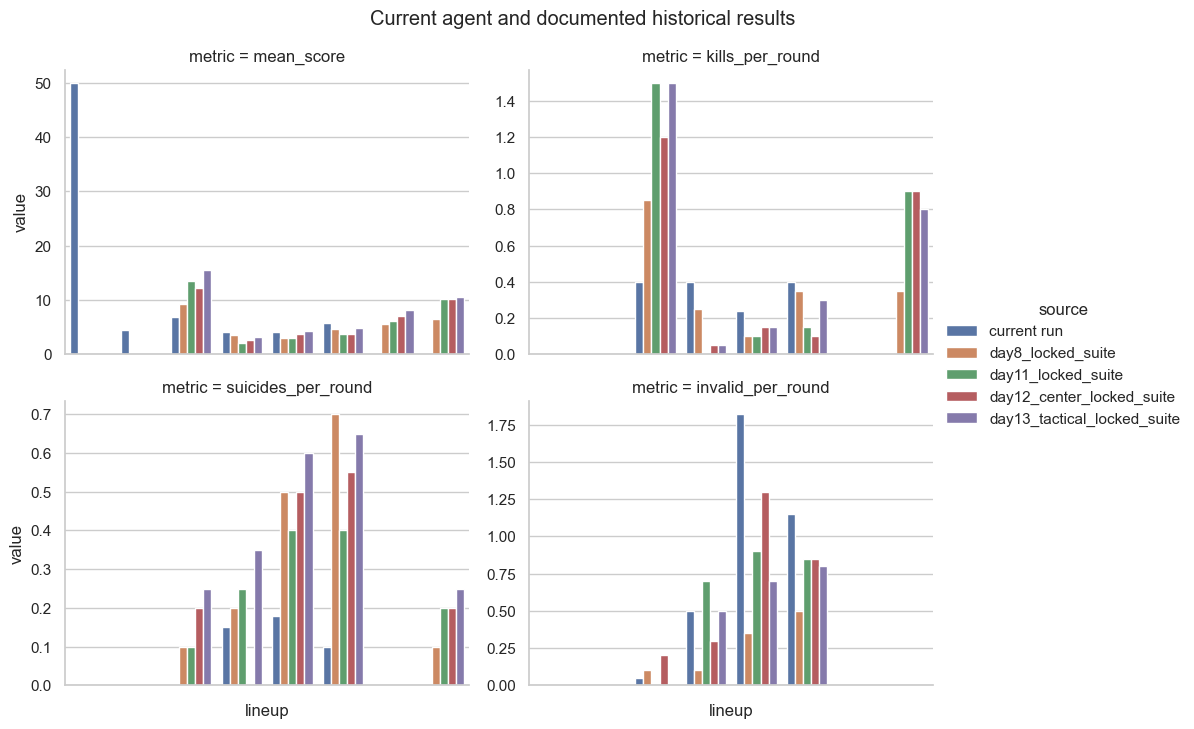

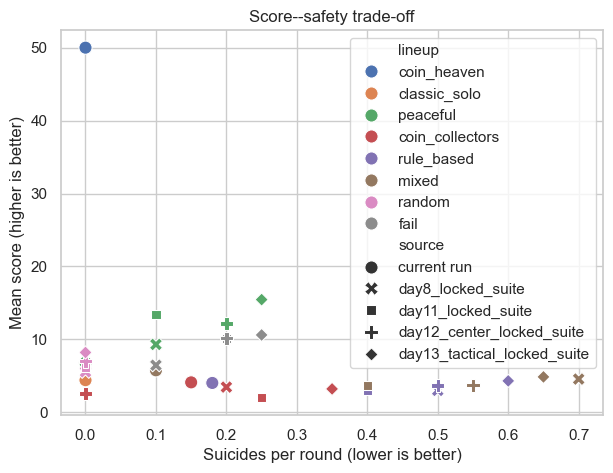

In [10]:
if not baseline_table.empty:
    plot_table = baseline_table.melt(
        id_vars=['source', 'task', 'lineup'],
        value_vars=['mean_score', 'kills_per_round', 'suicides_per_round', 'invalid_per_round'],
        var_name='metric', value_name='value',
    )
    g = sns.catplot(
        data=plot_table, x='lineup', y='value', hue='source', col='metric',
        kind='bar', col_wrap=2, sharey=False, height=3.6, aspect=1.35,
    )
    g.set_xticklabels(rotation=30, ha='right')
    g.fig.suptitle('Current agent and documented historical results', y=1.03)
    plt.show()

    if {'mean_score', 'suicides_per_round'}.issubset(baseline_table.columns):
        plt.figure(figsize=(7, 5))
        sns.scatterplot(
            data=baseline_table, x='suicides_per_round', y='mean_score',
            hue='lineup', style='source', s=90,
        )
        plt.title('Score--safety trade-off')
        plt.xlabel('Suicides per round (lower is better)')
        plt.ylabel('Mean score (higher is better)')
        plt.show()

## 9. Promotion checklist

Before replacing the main checkpoint, record the following for both baseline and candidate:

1. checkpoint SHA-256 and code commit;
2. training seeds, evaluation seeds, opponents, and number of rounds;
3. mean score, coins, crates, kills, suicides, invalid actions, and action latency;
4. at least one fixed-seed visual replay when aggregate metrics reveal a trade-off;
5. one stated reason to promote or reject the candidate.

For a new learning algorithm (e.g., PPO or behaviour-cloning warm-start RL), retain the same four task specifications and evaluation metrics. First compare it under the same safety mask and feature representation; afterwards, report any full-controller comparison separately.